# 09 — Class-Imbalance Handling

[Previous](./08_Outlier_Handling.ipynb) | [Repository guide](../README.md) | [Next](./10_Model_Comparison.ipynb)

> This public copy includes the saved Kaggle outputs, so every table, chart, and score can be inspected on GitHub.

**Goal:** test whether changing the class balance helps predict scored penalties.

Every sampler is fitted only on the training part of each validation fold.

### Read the setup

- `import` loads a Python tool; `as` gives it a short name.
- `pd` handles tables, `np` handles numerical calculations, and `plt` draws charts.
- The `sklearn` tools implement the methods explained in this chapter.


In [1]:
# Tables, numerical calculations, and charts.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import parallel_backend
from imblearn.combine import SMOTEENN, SMOTETomek
from imblearn.over_sampling import ADASYN, BorderlineSMOTE, RandomOverSampler, SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler, TomekLinks
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# The column we want to predict: 1 = scored, 0 = missed.
TARGET = "is_scored"
# These identifier columns are excluded from the course's model inputs.
ID_COLUMNS = ["id", "kicker_id", "keeper_id", "match_id"]
# A fixed seed makes randomized splits and experiments repeatable.
RANDOM_STATE = 42

# Optional display settings: readable tables and chart grids.
pd.set_option("display.float_format", "{:.4f}".format)
plt.style.use("seaborn-v0_8-whitegrid")


### Load the competition data

Attach the competition under Kaggle's **Input** panel. `DATA_DIR` is its folder;
`pd.read_csv` opens a CSV as a table. `train` contains known answers; `test`
contains the rows we will eventually predict.

For Colab, upload the extracted CSV files and set `DATA_DIR` to `/content`;
the [repository guide](../README.md#colab) explains the output-path change.


In [3]:
DATA_DIR = "/kaggle/input/competitions/penalty-kick-outcome-prediction-challenge"

train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")

# Check that only train contains labels and both files have the same inputs.
assert TARGET in train and TARGET not in test
assert set(train.columns) - {TARGET} == set(test.columns)

print(f"Source: {DATA_DIR}")
print(f"Train: {train.shape} | Test: {test.shape}")


Source: /kaggle/input/competitions/penalty-kick-outcome-prediction-challenge
Train: (20000, 20) | Test: (6000, 19)


## 1. Is the target imbalanced?

The **majority class** has more rows; the **minority class** has fewer. A severe imbalance can let a model ignore the minority class and still obtain high accuracy.

Here, `1` means scored and `0` means not scored. The **imbalance ratio** below is minority rows divided by majority rows; a value near `1` is fairly balanced.


,rows,percent
Not scored (0),10999,54.9950
Scored (1),9001,45.0050


Minority / majority ratio: 0.818


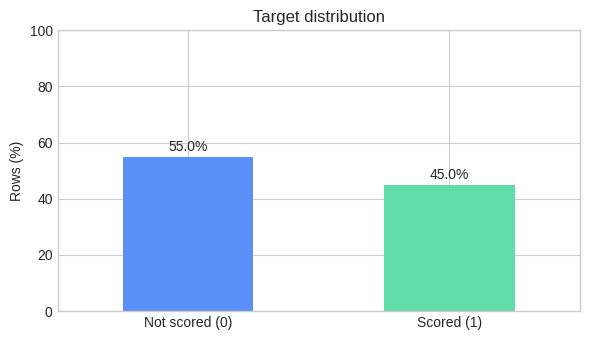

In [4]:
y = train[TARGET].astype(int)
class_counts = y.value_counts().sort_index()
class_percent = y.value_counts(normalize=True).sort_index().mul(100)
balance_table = pd.DataFrame({"rows": class_counts, "percent": class_percent})
balance_table.index = ["Not scored (0)", "Scored (1)"]
display(balance_table)

imbalance_ratio = class_counts.min() / class_counts.max()
print(f"Minority / majority ratio: {imbalance_ratio:.3f}")

ax = balance_table["percent"].plot.bar(
    figsize=(6, 3.5), color=["#5b8ff9", "#61dDAA"], rot=0, legend=False,
    title="Target distribution",
)
ax.set(xlabel="", ylabel="Rows (%)", ylim=(0, 100))
for patch, value in zip(ax.patches, balance_table["percent"]):
    ax.text(patch.get_x() + patch.get_width() / 2, value + 2, f"{value:.1f}%", ha="center")
plt.tight_layout()
plt.show()


## 2. Keep validation stratified

**Stratified K-fold** keeps nearly the same class proportions in every fold. This makes method comparisons fair and prevents one fold from receiving unusually few positive examples.


In [5]:
FEATURE_GROUPS = {
    "Relative ability": ["skill_advantage", "foot_difference", "skill_ratio_share", "skill_proxy"],
    "Match state": [
        "is_close_game", "is_losing", "is_tied", "is_winning", "match_status",
        "home_crowd_aligned", "is_poor_pitch", "final_extra_time",
    ],
    "Pressure components": ["pressure_index", "low_pressure", "late_minute", "extreme_pressure", "is_weak_player"],
    "Problem interactions": [
        "skill_gap_x_low_pressure", "disaster_combo", "pressure_x_weak",
        "pressure_skill", "keeper_pressure", "late_close_game",
    ],
    "Nonlinear and cyclical": [
        "player_form_squared", "keeper_form_squared", "skill_to_keeper_ratio",
        "score_x_minute", "minute_sin", "minute_cos", "humidity_sq_weak",
        "skill_keeper_product", "humidity_minute_interaction",
    ],
    "Composure proxies": ["clutch_boost", "choke_penalty"],
}


def add_engineered_features(frame):
    result = frame.copy()
    player_pct = result["player_last5_scored_percent"] / 100
    keeper_pct = result["goalkeeper_last5_saved_percent"] / 100
    minute_norm = result["minute_taken"] / 120
    humidity_norm = result["weather_humidity"] / 100
    score_diff = result["current_score_diff"]
    # A comparison gives True/False; astype(float) turns it into 1.0/0.0.
    close_game = (score_diff.abs() <= 1).astype(float)

    # Relative-ability hypotheses.
    result["skill_advantage"] = result["player_last5_scored_percent"] - result["goalkeeper_last5_saved_percent"]
    result["foot_difference"] = result["strong_foot_usage"] - result["weak_foot_usage"]
    result["skill_ratio_share"] = player_pct / (player_pct + keeper_pct + 0.10)
    result["skill_proxy"] = (
        0.3 * result["strong_foot_usage"]
        + 0.2 * result["foot_difference"]
        + 0.5 * player_pct
    ).clip(0, 1)

    # Match-state hypotheses derived from score, timing, and context.
    result["is_close_game"] = close_game
    result["is_losing"] = (score_diff < 0).astype(float)
    result["is_tied"] = (score_diff == 0).astype(float)
    result["is_winning"] = (score_diff > 0).astype(float)
    result["match_status"] = np.select(
        [(score_diff > 0), (score_diff == 0), (score_diff < 0)], [0.0, 1.0, 2.0], default=np.nan
    )
    result["home_crowd_aligned"] = (
        (result["home_or_away"] == "Home") & (result["crowd_behind_goal"] == "Home")
    ).astype(float)
    result["is_poor_pitch"] = (result["pitch_condition"] == "Poor").astype(float)
    result["final_extra_time"] = (
        (result["match_type"] == "Final") & (result["minute_taken"] > 90)
    ).astype(float)

    # Pressure hypothesis built from match type, time, and score state.
    pressure_map = {"League": 0.2, "Cup": 0.4, "Playoff": 0.5, "Final": 0.6, "Friendly": 0.1}
    match_pressure = result["match_type"].map(pressure_map).fillna(0.3)
    score_pressure = 1.0 / (score_diff.abs() + 1)
    result["pressure_index"] = (0.5 * match_pressure + 0.25 * minute_norm + 0.25 * score_pressure).clip(0, 1)
    result["low_pressure"] = 1 - result["pressure_index"]
    result["late_minute"] = (minute_norm - 0.625).clip(0, 1)
    result["extreme_pressure"] = (result["pressure_index"] > 0.75).astype(float)
    result["is_weak_player"] = (player_pct < 0.4).astype(float)

    # Interactions: one condition changes the effect of another.
    result["skill_gap_x_low_pressure"] = (player_pct - keeper_pct) * result["low_pressure"]
    result["disaster_combo"] = result["late_minute"] * result["is_losing"] * result["is_poor_pitch"]
    result["pressure_x_weak"] = result["pressure_index"] * result["is_weak_player"]
    result["pressure_skill"] = close_game * result["player_last5_scored_percent"]
    result["keeper_pressure"] = (score_diff <= 0).astype(float) * result["goalkeeper_last5_saved_percent"]
    result["late_close_game"] = close_game * minute_norm

    # Generic suggested candidates: useful to test even when the result rejects them.
    result["player_form_squared"] = result["player_last5_scored_percent"] ** 2
    result["keeper_form_squared"] = result["goalkeeper_last5_saved_percent"] ** 2
    result["skill_to_keeper_ratio"] = result["player_last5_scored_percent"] / (
        result["goalkeeper_last5_saved_percent"] + 1
    )
    result["score_x_minute"] = score_diff * result["minute_taken"]
    result["minute_sin"] = np.sin(2 * np.pi * (result["minute_taken"] / 90))
    result["minute_cos"] = np.cos(4 * np.pi * (result["minute_taken"] / 90))
    result["humidity_sq_weak"] = (humidity_norm ** 2) * result["weak_foot_usage"]
    result["skill_keeper_product"] = player_pct * keeper_pct
    result["humidity_minute_interaction"] = humidity_norm * result["minute_sin"]

    # Composure is hidden; skill_proxy is a visible, imperfect substitute.
    result["clutch_boost"] = (result["skill_proxy"] > 0.7).astype(float) * result["extreme_pressure"]
    result["choke_penalty"] = (result["skill_proxy"] < 0.3).astype(float) * result["extreme_pressure"]
    return result

X_original = train.drop(columns=[TARGET] + ID_COLUMNS)
X = add_engineered_features(X_original)
categorical_columns = X.select_dtypes(exclude=np.number).columns.tolist()
numerical_columns = X.select_dtypes(include=np.number).columns.tolist()
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def make_preprocessor():
    return ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), numerical_columns),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), categorical_columns),
    ])


## 3. Methods to compare

| Method | What it does | Main trade-off |
|---|---|---|
| No balancing | Keeps the original rows | Best reference when imbalance is mild |
| Class weights | Makes minority mistakes cost more | Keeps all rows; may reduce precision |
| Random oversampling | Duplicates minority rows | Simple; can overfit copies |
| Random undersampling | Removes majority rows | Fast; discards information |
| SMOTE | Interpolates between minority neighbors | Adds variety; can create unrealistic points |
| Borderline SMOTE | Synthesizes near the class boundary | Focuses on hard cases; may amplify overlap |
| ADASYN | Synthesizes more around hard minority rows | Adaptive; can amplify noise |
| Tomek links | Removes very close opposite-class pairs | Cleans overlap; does not fully balance |
| SMOTE–Tomek | SMOTE followed by Tomek cleaning | Adds then cleans; more complex |
| SMOTE–ENN | SMOTE followed by stronger neighbor cleaning | Can make a clear boundary; may remove many rows |

**Synthetic** means generated rather than recorded. Because preprocessing one-hot encodes categories, synthetic methods may create fractional category columns; that is a limitation to remember.


In [6]:
method_families = pd.DataFrame([
    ["No balancing", "Reference", "No"],
    ["Class weights", "Cost-sensitive", "No"],
    ["Random oversampling", "Oversampling", "Duplicates minority rows"],
    ["Random undersampling", "Undersampling", "Removes majority rows"],
    ["SMOTE", "Synthetic oversampling", "Adds generated minority rows"],
    ["Borderline SMOTE", "Synthetic oversampling", "Adds near the boundary"],
    ["ADASYN", "Synthetic oversampling", "Adds near difficult rows"],
    ["Tomek links", "Boundary cleaning", "Removes overlapping pairs"],
    ["SMOTE–Tomek", "Hybrid", "Adds, then cleans"],
    ["SMOTE–ENN", "Hybrid", "Adds, then cleans strongly"],
], columns=["method", "family", "row change"])
display(method_families.style.hide(axis="index"))


method,family,row change
No balancing,Reference,No
Class weights,Cost-sensitive,No
Random oversampling,Oversampling,Duplicates minority rows
Random undersampling,Undersampling,Removes majority rows
SMOTE,Synthetic oversampling,Adds generated minority rows
Borderline SMOTE,Synthetic oversampling,Adds near the boundary
ADASYN,Synthetic oversampling,Adds near difficult rows
Tomek links,Boundary cleaning,Removes overlapping pairs
SMOTE–Tomek,Hybrid,"Adds, then cleans"
SMOTE–ENN,Hybrid,"Adds, then cleans strongly"


### Concrete dataset example: what balancing changes

Class weights keep every row and change only the cost of mistakes. Oversampling adds minority rows, undersampling removes majority rows, and hybrid methods add rows before cleaning ambiguous neighbors.

The next table applies each sampler once to the prepared full training data only as a count illustration. The scored/not-scored balance is recalculated separately inside every validation fold during evaluation.


method,not scored rows,scored rows,total rows
Original / class weights,10999,9001,20000
Random oversampling,10999,10999,21998
Random undersampling,9001,9001,18002
SMOTE,10999,10999,21998
Borderline SMOTE,10999,10999,21998
ADASYN,10999,10380,21379
Tomek links,10438,9001,19439
SMOTE–Tomek,10613,10613,21226
SMOTE–ENN,7814,8186,16000


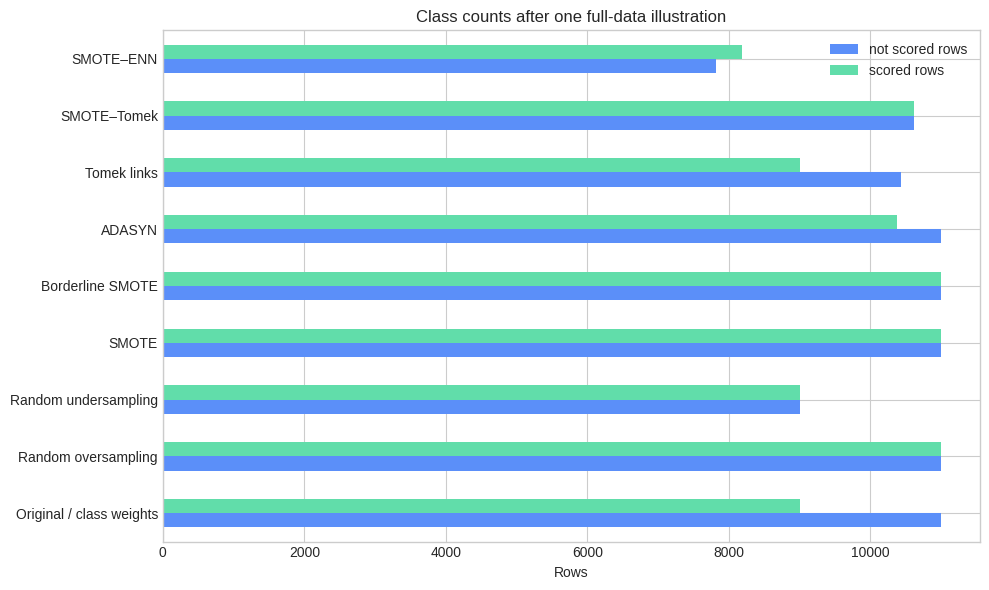

In [7]:
count_samplers = [
    ("Original / class weights", None),
    ("Random oversampling", RandomOverSampler(random_state=RANDOM_STATE)),
    ("Random undersampling", RandomUnderSampler(random_state=RANDOM_STATE)),
    ("SMOTE", SMOTE(random_state=RANDOM_STATE, k_neighbors=5)),
    ("Borderline SMOTE", BorderlineSMOTE(random_state=RANDOM_STATE, k_neighbors=5)),
    ("ADASYN", ADASYN(random_state=RANDOM_STATE, n_neighbors=5)),
    ("Tomek links", TomekLinks()),
    ("SMOTE–Tomek", SMOTETomek(random_state=RANDOM_STATE)),
    ("SMOTE–ENN", SMOTEENN(random_state=RANDOM_STATE)),
]

prepared_X = make_preprocessor().fit_transform(X, y)
count_rows = []
for name, sampler in count_samplers:
    if sampler is None:
        sampled_y = y.to_numpy()
    else:
        _, sampled_y = sampler.fit_resample(prepared_X, y)
    sampled_counts = pd.Series(sampled_y).value_counts()
    count_rows.append({
        "method": name,
        "not scored rows": sampled_counts.get(0, 0),
        "scored rows": sampled_counts.get(1, 0),
        "total rows": len(sampled_y),
    })

count_example = pd.DataFrame(count_rows)
display(count_example.style.hide(axis="index"))

plot_counts = count_example.set_index("method")[["not scored rows", "scored rows"]]
plot_counts.plot.barh(figsize=(10, 6), color=["#5b8ff9", "#61dDAA"], title="Class counts after one full-data illustration")
plt.xlabel("Rows")
plt.ylabel("")
plt.tight_layout()
plt.show()


## 4. Leakage-safe comparison

A **sampler** changes the training rows. It must run after preprocessing but inside each fold: validation rows are never duplicated, removed, or used to create synthetic samples.

We compare out-of-fold predictions with the same five splits and the same logistic-regression model.


In [8]:
experiments = [
    ("No balancing", None, None),
    ("Class weights", None, "balanced"),
    ("Random oversampling", RandomOverSampler(random_state=RANDOM_STATE), None),
    ("Random undersampling", RandomUnderSampler(random_state=RANDOM_STATE), None),
    ("SMOTE", SMOTE(random_state=RANDOM_STATE, k_neighbors=5), None),
    ("Borderline SMOTE", BorderlineSMOTE(random_state=RANDOM_STATE, k_neighbors=5), None),
    ("ADASYN", ADASYN(random_state=RANDOM_STATE, n_neighbors=5), None),
    ("Tomek links", TomekLinks(), None),
    ("SMOTE–Tomek", SMOTETomek(random_state=RANDOM_STATE), None),
    ("SMOTE–ENN", SMOTEENN(random_state=RANDOM_STATE), None),
]

rows = []
for name, sampler, class_weight in experiments:
    steps = [("preprocessor", make_preprocessor())]
    if sampler is not None:
        steps.append(("sampler", sampler))
    steps.append((
        "model",
        LogisticRegression(
            max_iter=10000,
            random_state=RANDOM_STATE,
            class_weight=class_weight,
        ),
    ))
    pipeline = ImbPipeline(steps)

    with parallel_backend("threading"):
        probabilities = cross_val_predict(
            pipeline, X, y, cv=cv, method="predict_proba", n_jobs=-1
        )[:, 1]
    predictions = (probabilities >= 0.5).astype(int)
    fold_f1 = [
        f1_score(y.iloc[index], predictions[index])
        for _, index in cv.split(X, y)
    ]
    rows.append({
        "method": name,
        "f1": f1_score(y, predictions),
        "f1_std": np.std(fold_f1, ddof=1),
        "precision": precision_score(y, predictions),
        "recall": recall_score(y, predictions),
        "balanced_accuracy": balanced_accuracy_score(y, predictions),
        "accuracy": accuracy_score(y, predictions),
        "roc_auc": roc_auc_score(y, probabilities),
    })

results = pd.DataFrame(rows).sort_values("f1", ascending=False).reset_index(drop=True)
display(results)


,method,f1,f1_std,precision,recall,balanced_accuracy,accuracy,roc_auc
0,Random undersampling,0.8848,0.0056,0.8766,0.8930,0.8951,0.8953,0.9624
1,No balancing,0.8847,0.0061,0.8916,0.8779,0.8953,0.8970,0.9625
2,ADASYN,0.8846,0.0058,0.8707,0.8989,0.8948,0.8944,0.9623
3,Class weights,0.8845,0.0055,0.8772,0.8920,0.8949,0.8952,0.9625
4,Tomek links,0.8845,0.0062,0.8799,0.8891,0.8949,0.8955,0.9624
5,Random oversampling,0.8840,0.0062,0.8756,0.8925,0.8944,0.8945,0.9624
6,SMOTE,0.8837,0.0056,0.8771,0.8905,0.8942,0.8945,0.9625
7,SMOTE–Tomek,0.8833,0.0059,0.8765,0.8901,0.8937,0.8941,0.9623
8,Borderline SMOTE,0.8829,0.0056,0.8633,0.9033,0.8932,0.8921,0.9621
9,SMOTE–ENN,0.8719,0.0068,0.8491,0.8960,0.8829,0.8815,0.9557


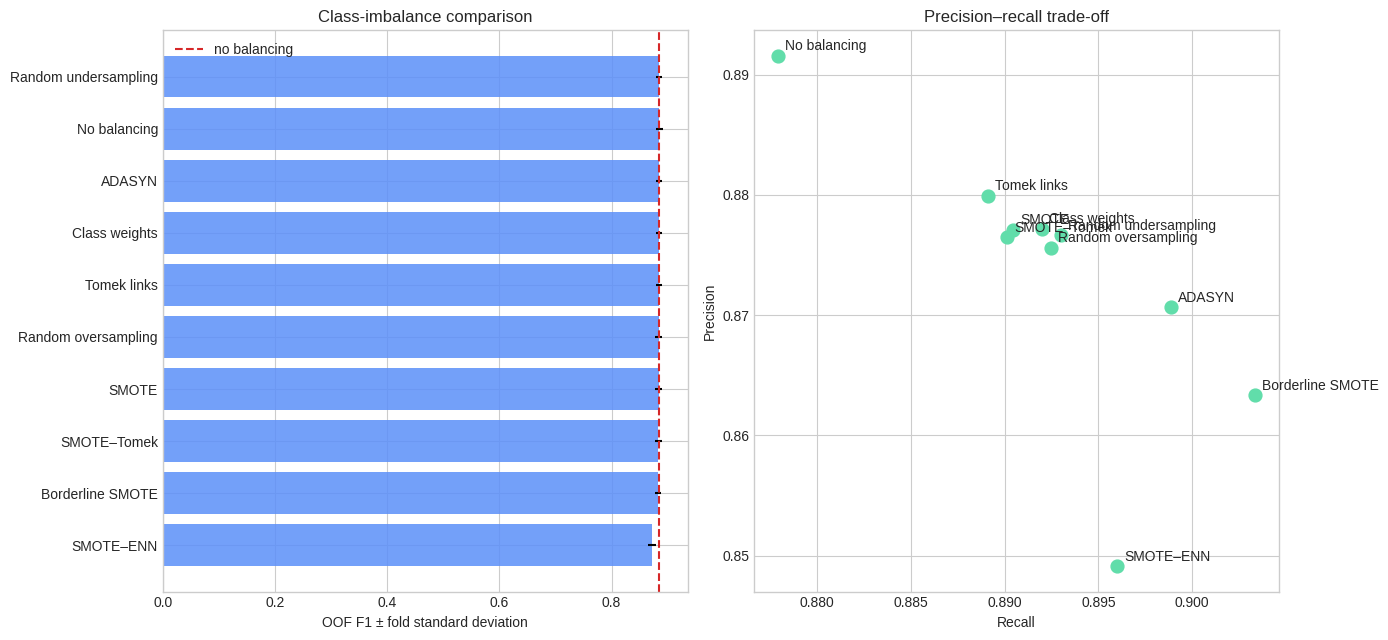

In [9]:
reference = results.loc[results["method"].eq("No balancing")].iloc[0]
ordered = results.sort_values("f1")

fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
axes[0].barh(
    ordered["method"], ordered["f1"], xerr=ordered["f1_std"],
    color="#5b8ff9", alpha=0.85,
)
axes[0].axvline(reference["f1"], color="#d62728", linestyle="--", label="no balancing")
axes[0].set(title="Class-imbalance comparison", xlabel="OOF F1 ± fold standard deviation", ylabel="")
axes[0].legend()

axes[1].scatter(results["recall"], results["precision"], s=85, color="#61dDAA")
for _, row in results.iterrows():
    axes[1].annotate(row["method"], (row["recall"], row["precision"]), xytext=(5, 4), textcoords="offset points")
axes[1].set(title="Precision–recall trade-off", xlabel="Recall", ylabel="Precision")

plt.tight_layout()
plt.show()


## 5. Freeze the validation decision

The choice below uses only out-of-fold predictions. Once printed, it is frozen: the later hidden-test reveal explains generalization but does not retroactively tune the method.


In [10]:
best = results.iloc[0]
gain = best["f1"] - reference["f1"]

print(f"No-balancing reference: F1 {reference['f1']:.4f}")
print(f"Best point estimate: {best['method']} | F1 {best['f1']:.4f} | change {gain:+.4f}")

if best["method"] == "No balancing" or gain < reference["f1_std"]:
    print("Decision: keep the original class distribution; the imbalance is mild and no gain is clearly stable.")
else:
    print(f"Decision: keep {best['method']} as the validated candidate.")


No-balancing reference: F1 0.8847
Best point estimate: Random undersampling | F1 0.8848 | change +0.0001
Decision: keep the original class distribution; the imbalance is mild and no gain is clearly stable.


## 6. Organizer-only post-competition audit

This section answers a different question: **did the validation conclusion transfer to the hidden test set?** It is not a replacement for validation and is not part of a competitor workflow.

Why the separation matters: if we inspect hidden-test F1 after every idea and then choose the winner, human decisions have fitted the test set. The reported test score becomes optimistic. Here the candidates and validation decision were fixed first, so this is a one-way teaching reveal.


Hidden test target distribution:


,rows (%)
is_scored,
0,49.9667
1,50.0333


,method,validation_f1,validation_precision,validation_recall,validation_accuracy,hidden_test_f1,hidden_test_precision,hidden_test_recall,hidden_test_accuracy,test_minus_validation_f1
8,Borderline SMOTE,0.8829,0.8633,0.9033,0.8921,0.8921,0.9376,0.8508,0.8970,0.0092
2,ADASYN,0.8846,0.8707,0.8989,0.8944,0.8879,0.9427,0.8391,0.8940,0.0034
0,Random undersampling,0.8848,0.8766,0.8930,0.8953,0.8836,0.9440,0.8304,0.8905,-0.0012
3,Class weights,0.8845,0.8772,0.8920,0.8952,0.8833,0.9432,0.8304,0.8902,-0.0013
5,Random oversampling,0.8840,0.8756,0.8925,0.8945,0.8830,0.9439,0.8294,0.8900,-0.0010
6,SMOTE,0.8837,0.8771,0.8905,0.8945,0.8827,0.9432,0.8294,0.8897,-0.0011
7,SMOTE–Tomek,0.8833,0.8765,0.8901,0.8941,0.8825,0.9428,0.8294,0.8895,-0.0007
4,Tomek links,0.8845,0.8799,0.8891,0.8955,0.8817,0.9458,0.8258,0.8892,-0.0028
1,No balancing,0.8847,0.8916,0.8779,0.8970,0.8760,0.9512,0.8118,0.8850,-0.0087
9,SMOTE–ENN,0.8719,0.8491,0.8960,0.8815,0.8746,0.9221,0.8318,0.8807,0.0027


Saved organizer-only audit: /kaggle/working/09_validation_vs_hidden_test.csv


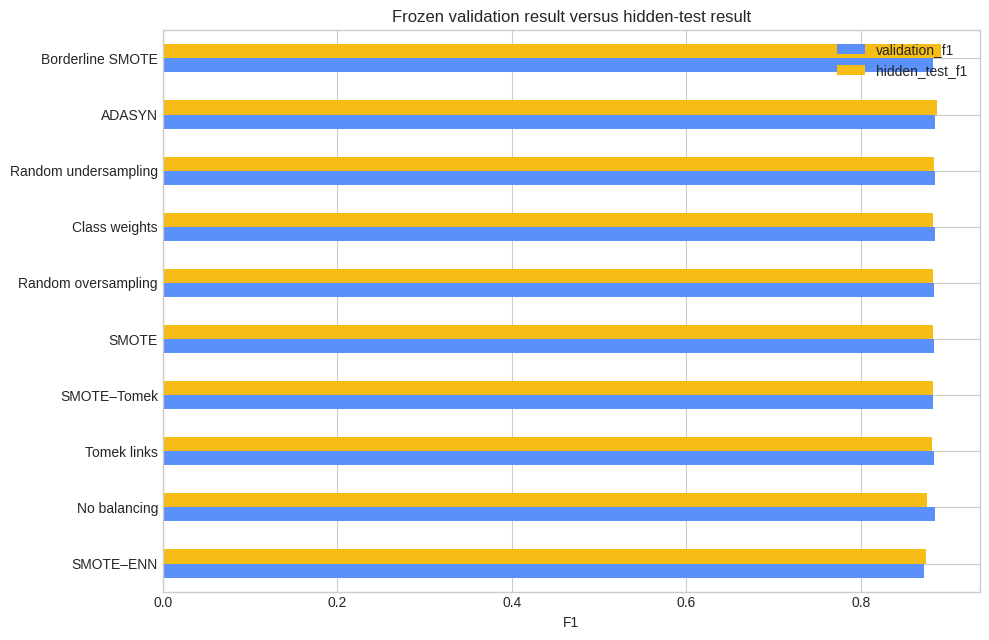

Interpretation: different rankings reveal a generalization gap; they do not authorize another tuning round on this test set.


In [11]:
# Path is used only to name the files saved in Kaggle's Output panel.
from pathlib import Path

# Optional, for the organizer after competition closure only.
# Set this to the exact private-label CSV path to enable the audit.
HIDDEN_LABEL_PATH = None
hidden_labels = None
if HIDDEN_LABEL_PATH is not None:
    hidden_labels = pd.read_csv(HIDDEN_LABEL_PATH)[["id", TARGET]]

if hidden_labels is None:
    print("Organizer-only audit skipped: attach the hidden-label file privately, then rerun this cell.")
else:
    hidden = test[["id"]].merge(hidden_labels, on="id", how="left", validate="one_to_one")
    if hidden[TARGET].isna().any():
        raise ValueError("Hidden labels do not cover every test id.")

    y_hidden = hidden[TARGET].astype(int)
    X_test = add_engineered_features(test.drop(columns=ID_COLUMNS))
    hidden_rows = []

    for name, sampler, class_weight in experiments:
        steps = [("preprocessor", make_preprocessor())]
        if sampler is not None:
            steps.append(("sampler", sampler))
        steps.append((
            "model",
            LogisticRegression(
                max_iter=10000,
                random_state=RANDOM_STATE,
                class_weight=class_weight,
            ),
        ))
        pipeline = ImbPipeline(steps)
        pipeline.fit(X, y)
        probabilities = pipeline.predict_proba(X_test)[:, 1]
        predictions = (probabilities >= 0.5).astype(int)
        hidden_rows.append({
            "method": name,
            "hidden_test_f1": f1_score(y_hidden, predictions),
            "hidden_test_precision": precision_score(y_hidden, predictions),
            "hidden_test_recall": recall_score(y_hidden, predictions),
            "hidden_test_accuracy": accuracy_score(y_hidden, predictions),
        })

    hidden_results = pd.DataFrame(hidden_rows)
    audit_results = results[["method", "f1", "precision", "recall", "accuracy"]].merge(
        hidden_results, on="method", validate="one_to_one"
    ).rename(columns={
        "f1": "validation_f1",
        "precision": "validation_precision",
        "recall": "validation_recall",
        "accuracy": "validation_accuracy",
    })
    audit_results["test_minus_validation_f1"] = (
        audit_results["hidden_test_f1"] - audit_results["validation_f1"]
    )
    audit_results = audit_results.sort_values("hidden_test_f1", ascending=False)

    print("Hidden test target distribution:")
    display(y_hidden.value_counts(normalize=True).sort_index().mul(100).rename("rows (%)").to_frame())
    display(audit_results)

    audit_output_dir = Path("/kaggle/working")
    audit_output_dir.mkdir(parents=True, exist_ok=True)
    audit_path = audit_output_dir / "09_validation_vs_hidden_test.csv"
    audit_results.to_csv(audit_path, index=False)
    print(f"Saved organizer-only audit: {audit_path}")

    comparison_plot = audit_results.set_index("method")[["validation_f1", "hidden_test_f1"]].sort_values("hidden_test_f1")
    comparison_plot.plot.barh(figsize=(10, 6.5), color=["#5b8ff9", "#f6bd16"], title="Frozen validation result versus hidden-test result")
    plt.xlabel("F1")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()

    print("Interpretation: different rankings reveal a generalization gap; they do not authorize another tuning round on this test set.")


### How to read the reveal

- If a balancing method improves both validation and hidden-test F1, the evidence is consistent.
- If validation is flat but hidden-test F1 improves, the test distribution favors that method; this is useful retrospective evidence, not a reusable validation rule.
- If hidden-test rankings differ strongly, future competitions need a validation split that better represents the expected test distribution.


## Other useful alternatives

- **SMOTENC:** performs synthetic sampling while treating selected columns as categorical; more faithful than interpolating one-hot columns, but needs a different preprocessing order.
- **NearMiss:** keeps majority rows close to minority rows; can discard much of the majority distribution.
- **Balanced Random Forest:** trains each tree on a balanced sample; compare it in the tree-model phase.
- **EasyEnsemble:** trains several models on different balanced subsets; useful for severe imbalance.
- **Focal loss:** emphasizes hard examples in neural networks; unnecessary for this logistic baseline.

The ten methods above already cover unchanged data, cost weighting, over/under-sampling, synthetic sampling, boundary cleaning, and hybrids.


In [12]:
# Path is used only to name the files saved in Kaggle's Output panel.
from pathlib import Path

results_dir = Path("/kaggle/working")
results_dir.mkdir(parents=True, exist_ok=True)
output_path = results_dir / "09_class_imbalance_handling.csv"
results.to_csv(output_path, index=False)
print(f"Saved: {output_path}")


Saved: /kaggle/working/09_class_imbalance_handling.csv


## Why the class-imbalance decision is justified

**Technical evidence:** the minority/majority ratio is measured directly, ten representative methods use identical stratified folds, and their precision–recall changes are visible. The validation decision is printed before any hidden-test audit.

**Theoretical reason:** resampling is designed for a representation problem, not as a universal improvement. Hidden labels can explain whether the frozen choice transferred, but using them repeatedly to select methods would convert the test set into a validation set and make the final estimate optimistic.
